<div align="center">

# PROJECT ODIN
### Retention Budget Optimisation: Decision Analytics Report

</div>

| | |
|---|---|
| **Client** | Aurvandil Media, a pan-European subscription streaming service *(fictional client used for this case study)* |
| **Engagement** | Allocation of the retention-campaign budget across at-risk subscribers |
| **Business question** | *With a fixed budget, which subscribers should receive a retention offer to maximise expected net financial benefit?* |
| **Deliverables** | This report · the reusable `odin` optimisation package · exported tables and charts |
| **Version** | 2.1, November 2026 |
| **Data classification** | Synthetic replica. Contains **no real customer data**. |

---

## Executive summary

**Recommendation:** replace the current *"highest churn score first"* targeting rule with **value-based portfolio optimisation** (0/1 Knapsack). It chooses the combination of subscribers that maximises expected net benefit within the budget.

| | Current rule (risk-first) | **Optimised portfolio** | Change |
|---|---:|---:|---:|
| **Pilot**: 30 high-value accounts, €500 | €1,048 | **€3,001** | **2.9×** |
| **Full base**: 5,000 subscribers, €25,000 | €20,438 | **€23,405** | **+€2,967 (+15%)** |
| Probability the pilot campaign loses money | 16.1% | **7.3%** | −8.8 pp |

*Values are expected net benefit (retained value minus offer cost) at an assumed 50% offer success rate.*

**Key findings**

1. **Risk alone is the wrong target.** The best pilot accounts combine above-average risk with high lifetime value and cheap offers. None of them is the single riskiest account.
2. **The answer is provably optimal and robust.** It is verified against exhaustive search, and the recommended pilot portfolio is identical across every tested offer success rate from 10% to 95%.
3. **Targeting quality matters more as margins thin.** On the full base, random targeting barely breaks even (a 36% chance of a loss), while the optimised campaign is profitable in all 20,000 simulated scenarios.
4. **Budget has diminishing returns.** At €25k, the next euro of budget returns about **€0.59** of net benefit, down from €1.05 at €10k. This gives a clear basis for sizing future budgets.
5. **Where the budget goes:** monthly-contract subscribers, Basic and Standard plans, and paid-search and partner-bundle acquisitions. These are high-churn segments with affordable offers.
6. **The next gains come from better decisions, not a bigger budget.** Choosing the offer per subscriber adds about 23%, and per-subscriber uplift from a randomised test changes the answer more than anything else (Part C).

---

### Report structure

| Section | Question answered |
|---|---|
| 1. Business context | Why is "contact the riskiest customers" not good enough? |
| 2. Analytical approach | How do we turn risk scores into a financially optimal decision? |
| 3. Setup | Configuration and assumptions in one place |
| **Part A: Pilot cohort** (30 high-value accounts) | Does optimisation beat the current rule, and is the answer provably optimal and robust? |
| **Part B: Full subscriber base** (5,000 accounts) | What drives churn, how good is the score, and where should a €25k budget go? |
| **Part C: Beyond the base model** | What if offers vary, capacity is limited, or subscribers respond differently? |
| 4. Recommendations | What should the client do next? |
| 5. Limitations | What the analysis can and cannot claim |
| Appendix | Reproducibility and exported artefacts |

# 1. Business context

Aurvandil Media loses a meaningful share of its subscribers every year. The retention team can win some of them back with incentives such as free months or discounted upgrades. Every incentive costs money, and the **quarterly retention budget is fixed**.

The team's current rule is **"contact the subscribers with the highest churn score first"**. It is intuitive, but it ignores two things:

| Blind spot | Consequence |
|---|---|
| **Value**: a high-risk subscriber may be worth very little | Budget is spent protecting low-value accounts |
| **Cost**: offers differ in price by plan | Cheap, high-value saves are crowded out by expensive ones |
| **Combination**: taking customers one at a time ignores how they fit together | Budget is left unused or allocated to a sub-optimal mix |

The decision is therefore not *"who is most likely to leave?"* but:

> **Which combination of subscribers maximises total expected net benefit without exceeding the budget?**

This is a budget-constrained combinatorial optimisation problem, the **0/1 Knapsack problem**.

# 2. Analytical approach

### 2.1 Customer economics

For every subscriber $i$, with churn score $P_i$, lifetime value $CLV_i$, offer cost $C_i$ and assumed offer success rate $r$:

$$
ERV_i = P_i \times CLV_i \times r \qquad\qquad ENB_i = ERV_i - C_i \qquad\qquad r^{*}_i = \frac{C_i}{P_i \times CLV_i}
$$

* **ERV**: *expected retained value*, the value at risk times the chance the offer prevents the loss.
* **ENB**: *expected net benefit*, ERV minus the offer cost. This is the quantity we maximise.
* **r\***: *break-even success rate*, the minimum offer effectiveness at which the offer pays for itself.

### 2.2 Portfolio optimisation

$$
\max_{x}\; \sum_i x_i \, ENB_i \quad \text{subject to} \quad \sum_i x_i \, C_i \le B, \qquad x_i \in \{0,1\}
$$

The model is solved **exactly** by dynamic programming in $O(n \cdot B)$ time. Subscribers with $ENB_i \le 0$ are excluded, because they can only lower the objective.

### 2.3 Strategies compared

| Strategy | Rule | Role |
|---|---|---|
| Random | Seeded shuffle, take each subscriber whose cost still fits | Floor / sanity check |
| Highest churn probability | Rank by score, take each subscriber whose cost still fits | **Client's current practice** |
| Value density (greedy) | Rank by ENB ÷ cost | Strong heuristic benchmark |
| **Knapsack optimisation** | Exact optimum | **Proposed method** |

### 2.4 Evaluation

* **Primary metric:** total expected net benefit (€).
* **Supporting metrics:** spend, ROI (ENB ÷ spend), share of the optimum, and the probability that the realised result is a loss (Monte Carlo).
* **Retrospective only:** actual churners among the selected subscribers. This is descriptive and is not evidence that the offers *caused* retention.

# 3. Setup and assumptions

All logic lives in the tested `odin` package (`src/odin/`), so this report and the command-line tool always produce identical numbers. Every scenario assumption is declared once, below.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)

# Resolve the repository root so the report runs from any working directory.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "odin").exists())
sys.path.insert(0, str(ROOT / "src"))

import odin
from odin import add_expected_value, brute_force_selection, knapsack_selection, load_customers
from odin.economics import break_even_success_rate
from odin.evaluation import (compare_strategies, evaluate_selection, optimality_gap, run_strategies,
                             score_diagnostics, segment_allocation)
from odin.sensitivity import (budget_sensitivity, portfolio_stability, sensitivity_grid,
                              success_rate_sensitivity)
from odin.simulation import simulate_net_benefit, summarise_simulations
from odin.data import validation_report

# ---- Scenario assumptions -------------------------------------------------
SUCCESS_RATE = 0.50          # assumed probability an offer prevents a churn (scenario input)
SEED = 42                    # reproducibility of random baseline and simulations
MC_RUNS = 20_000             # Monte Carlo simulations per portfolio

PILOT_FILE = Path("data/raw/project_odin_customers.csv")
PILOT_BUDGET = 500           # € for the 30-account pilot

BASE_FILE = Path("data/synthetic/customer_base_5000.csv")
BASE_BUDGET = 25_000         # € quarterly retention budget for the full base

# ---- Output locations (relative to the repository root) -------------------
OUT = Path("outputs/report")
FIG, TAB = OUT / "figures", OUT / "tables"
(ROOT / FIG).mkdir(parents=True, exist_ok=True)
(ROOT / TAB).mkdir(parents=True, exist_ok=True)

COLORS = {"Random": "#9AA5B1", "Highest Churn Probability": "#E07A5F",
          "Value Density (Greedy)": "#F2CC8F", "Knapsack Optimization": "#3D5A80"}
ACCENT, MUTED = "#3D5A80", "#9AA5B1"
plt.rcParams.update({"figure.figsize": (10, 5), "axes.titlesize": 13, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110,
                     "savefig.dpi": 160, "savefig.bbox": "tight"})
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

def save(fig, name):
    fig.savefig(ROOT / FIG / name)
    plt.show()

def euro(v):
    return f"€{v:,.0f}"

print(f"odin package v{odin.__version__} | pandas {pd.__version__} | numpy {np.__version__}")
print(f"Assumed offer success rate: {SUCCESS_RATE:.0%} | pilot budget: {euro(PILOT_BUDGET)} | "
      f"full-base budget: {euro(BASE_BUDGET)}")

odin package v1.1.0 | pandas 2.2.2 | numpy 1.26.4
Assumed offer success rate: 50% | pilot budget: €500 | full-base budget: €25,000


---
# Part A: Pilot cohort (30 high-value accounts)

Account management flagged 30 high-value subscribers for a pilot campaign with a **€500 budget**. The pilot is small enough to inspect every decision by hand and to **prove** the optimiser's answer by exhaustive search.

## A1. Data validation

In [2]:
pilot_raw = load_customers(ROOT / PILOT_FILE)
checks = validation_report(pilot_raw)
display(pd.DataFrame({"Check": list(checks), "Result": ["PASS" if v else "FAIL" for v in checks.values()]})
        .set_index("Check"))
print(f"{len(pilot_raw)} accounts | {pilot_raw['Actual_Churn'].sum()} observed churners")

,Result
Check,
All required columns are present,PASS
Dataset is not empty,PASS
Customer IDs are unique,PASS
No missing values,PASS
Actual churn contains only 0 and 1,PASS
Churn probabilities are between 0 and 1,PASS
CLV values are positive,PASS
Offer costs are positive,PASS
Offer costs are whole euros,PASS


30 accounts | 15 observed churners


All structural checks pass: unique IDs, no missing values, binary outcomes, valid probabilities and positive whole-euro costs. These are *technical* validity checks. They confirm that the file is usable, not that it represents reality.

## A2. Pilot profile

,mean,std,min,50%,max
Predicted_Churn_Probability,0.55,0.24,0.14,0.61,0.88
Estimated_CLV,995.50,469.35,229.00,903.50,"1,745.00"
Retention_Offer_Cost,100.30,33.66,40.00,104.00,148.00


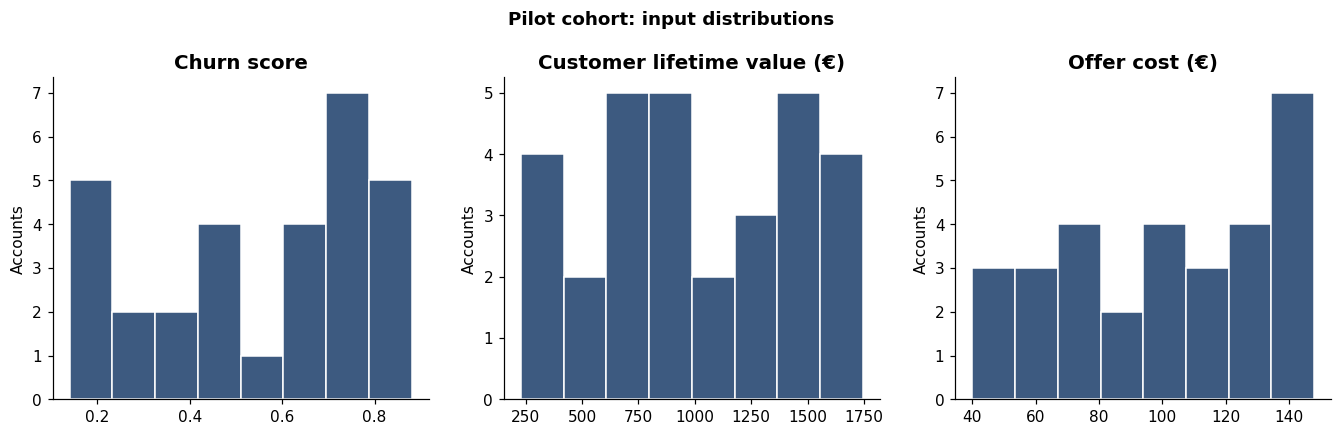

In [3]:
display(pilot_raw[["Predicted_Churn_Probability", "Estimated_CLV", "Retention_Offer_Cost"]]
        .describe().T[["mean", "std", "min", "50%", "max"]])

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (col, title) in zip(axes, [("Predicted_Churn_Probability", "Churn score"),
                                   ("Estimated_CLV", "Customer lifetime value (€)"),
                                   ("Retention_Offer_Cost", "Offer cost (€)")]):
    ax.hist(pilot_raw[col], bins=8, color=ACCENT, edgecolor="white")
    ax.set_title(title); ax.set_ylabel("Accounts")
fig.suptitle("Pilot cohort: input distributions", fontweight="bold", y=1.04)
save(fig, "A2_pilot_profile.png")

Risk, value and cost all vary widely and are only weakly related to each other. That is exactly the situation in which ranking on risk alone goes wrong.

## A3. Customer economics

In [4]:
pilot = add_expected_value(pilot_raw, SUCCESS_RATE)
pilot["Break_Even_Success_Rate"] = break_even_success_rate(pilot)

print(f"Offers with positive expected net benefit: {(pilot['Expected_Net_Benefit'] > 0).sum()} of {len(pilot)}")
display(pilot.sort_values("Expected_Net_Benefit", ascending=False)
        [["Customer_ID", "Predicted_Churn_Probability", "Estimated_CLV", "Retention_Offer_Cost",
          "Expected_Retained_Value", "Expected_Net_Benefit", "Break_Even_Success_Rate"]]
        .head(10).style.format({"Predicted_Churn_Probability": "{:.2f}", "Estimated_CLV": "€{:,.0f}",
                                "Retention_Offer_Cost": "€{:,.0f}", "Expected_Retained_Value": "€{:,.0f}",
                                "Expected_Net_Benefit": "€{:,.0f}", "Break_Even_Success_Rate": "{:.0%}"})
        .hide(axis="index"))

Offers with positive expected net benefit: 25 of 30


Customer_ID,Predicted_Churn_Probability,Estimated_CLV,Retention_Offer_Cost,Expected_Retained_Value,Expected_Net_Benefit,Break_Even_Success_Rate
C021,0.71,"€1,699",€73,€603,€530,6%
C024,0.81,"€1,516",€95,€614,€519,8%
C007,0.71,"€1,640",€68,€582,€514,6%
C001,0.72,"€1,669",€92,€601,€509,8%
C004,0.66,"€1,745",€86,€576,€490,7%
C030,0.65,"€1,515",€53,€492,€439,5%
C025,0.72,"€1,171",€101,€422,€321,12%
C019,0.76,"€1,060",€97,€403,€306,12%
C020,0.61,"€1,239",€125,€378,€253,17%
C006,0.88,€654,€74,€288,€214,13%


The ten most valuable offers have break-even success rates of 17% or less, so they pay off even if the offer works far less often than the assumed 50%. Only **two of the five riskiest accounts** make this list. The other three are worth too little relative to the cost of their offer.

## A4. Strategy comparison

,Selected Customers,Total Spending (€),Expected Retained Value (€),Expected Net Benefit (€),ROI,Actual Churners Captured,Actual Churn Capture Rate,Share of Optimum
Strategy,,,,,,,,
Random,5,€462,"€1,028",€566,1.23x,1,7%,19%
Highest Churn Probability,5,€481,"€1,529","€1,048",2.18x,5,33%,35%
Value Density (Greedy),6,€467,"€3,468","€3,001",6.43x,5,33%,100%
Knapsack Optimization,6,€467,"€3,468","€3,001",6.43x,5,33%,100%


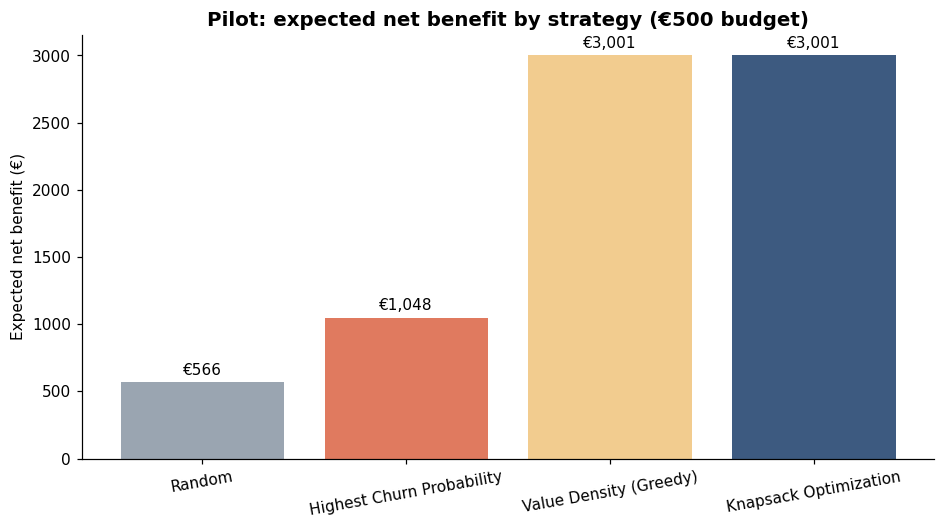

In [5]:
pilot_sel = run_strategies(pilot, PILOT_BUDGET, seed=SEED)
pilot_cmp = compare_strategies(pilot, pilot_sel)
pilot_cmp["Share of Optimum"] = optimality_gap(pilot_cmp)
display(pilot_cmp.style.format({"Selected Customers": "{:.0f}", "Total Spending (€)": "€{:,.0f}",
        "Expected Retained Value (€)": "€{:,.0f}", "Expected Net Benefit (€)": "€{:,.0f}", "ROI": "{:.2f}x",
        "Actual Churners Captured": "{:.0f}", "Actual Churn Capture Rate": "{:.0%}",
        "Share of Optimum": "{:.0%}"}))

fig, ax = plt.subplots()
vals = pilot_cmp["Expected Net Benefit (€)"]
bars = ax.bar(vals.index, vals.values, color=[COLORS[i] for i in vals.index])
ax.bar_label(bars, [euro(v) for v in vals.values], padding=3)
ax.set_title(f"Pilot: expected net benefit by strategy ({euro(PILOT_BUDGET)} budget)")
ax.set_ylabel("Expected net benefit (€)"); ax.tick_params(axis="x", rotation=10)
save(fig, "A4_pilot_strategy_comparison.png")

For almost the same spend, the optimised portfolio is worth about **2.9 times the client's current risk-first rule** and **5.3 times random selection**. The greedy value-density heuristic happens to reach the optimum on this cohort. Section A6 shows that it does not at every budget.

## A5. Recommended pilot portfolio

Customer_ID,Predicted_Churn_Probability,Estimated_CLV,Retention_Offer_Cost,Expected_Net_Benefit,Break_Even_Success_Rate
C021,0.71,"€1,699",€73,€530,6%
C024,0.81,"€1,516",€95,€519,8%
C007,0.71,"€1,640",€68,€514,6%
C001,0.72,"€1,669",€92,€509,8%
C004,0.66,"€1,745",€86,€490,7%
C030,0.65,"€1,515",€53,€439,5%


6 accounts | spend €467 of €500 | expected net benefit €3,001


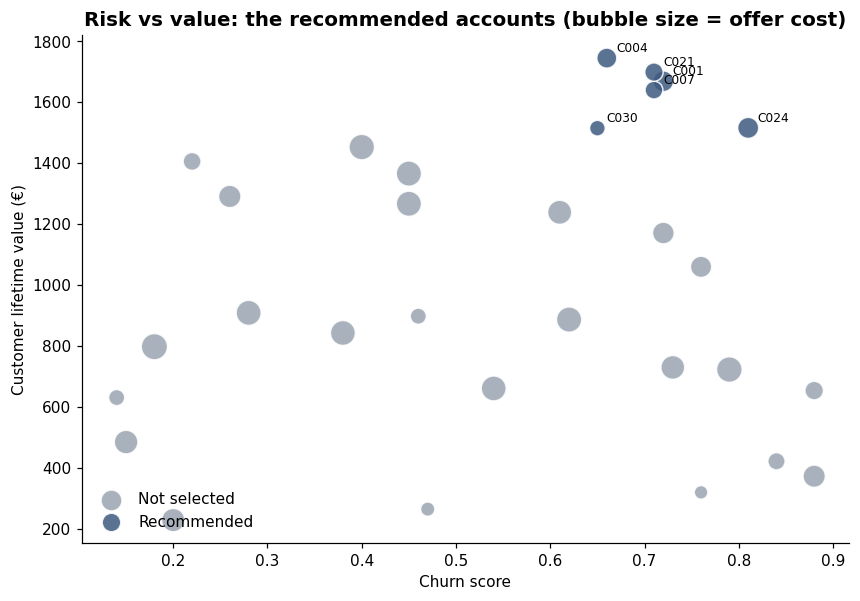

In [6]:
pilot_ids = pilot_sel["Knapsack Optimization"]
portfolio = pilot[pilot["Customer_ID"].isin(pilot_ids)].sort_values("Expected_Net_Benefit", ascending=False)
display(portfolio[["Customer_ID", "Predicted_Churn_Probability", "Estimated_CLV", "Retention_Offer_Cost",
                   "Expected_Net_Benefit", "Break_Even_Success_Rate"]]
        .style.format({"Predicted_Churn_Probability": "{:.2f}", "Estimated_CLV": "€{:,.0f}",
                       "Retention_Offer_Cost": "€{:,.0f}", "Expected_Net_Benefit": "€{:,.0f}",
                       "Break_Even_Success_Rate": "{:.0%}"}).hide(axis="index"))
spend = portfolio["Retention_Offer_Cost"].sum()
print(f"{len(portfolio)} accounts | spend {euro(spend)} of {euro(PILOT_BUDGET)} | "
      f"expected net benefit {euro(portfolio['Expected_Net_Benefit'].sum())}")

fig, ax = plt.subplots(figsize=(9, 6))
picked = pilot["Customer_ID"].isin(pilot_ids)
for mask, color, label in [(~picked, MUTED, "Not selected"), (picked, ACCENT, "Recommended")]:
    ax.scatter(pilot.loc[mask, "Predicted_Churn_Probability"], pilot.loc[mask, "Estimated_CLV"],
               s=pilot.loc[mask, "Retention_Offer_Cost"] * 2, c=color, alpha=0.85, edgecolor="white", label=label)
for _, r in pilot[picked].iterrows():
    ax.annotate(r["Customer_ID"], (r["Predicted_Churn_Probability"], r["Estimated_CLV"]),
                xytext=(6, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("Churn score"); ax.set_ylabel("Customer lifetime value (€)")
ax.set_title("Risk vs value: the recommended accounts (bubble size = offer cost)")
ax.legend(frameon=False, loc="lower left")
save(fig, "A5_pilot_risk_vs_value.png")

The recommended accounts sit in the **upper-right**: they combine above-average risk with the highest lifetime values and moderate offer costs. None of them is the single riskiest account.

## A6. Verification and heuristic gap

Verified: dynamic programming == exhaustive search.


,Random,Highest Churn Probability,Value Density (Greedy)
min,-1.3%,18.3%,91.3%
mean,23.9%,45.6%,99.0%


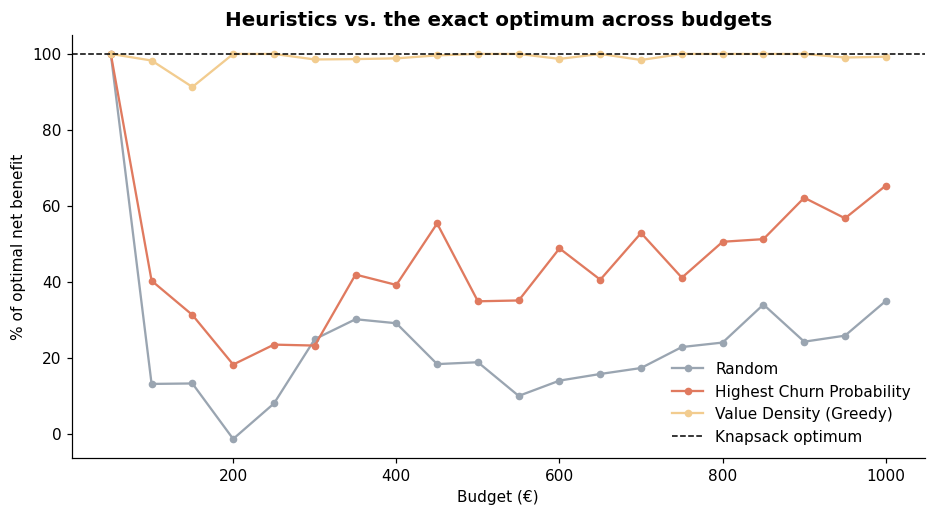

In [7]:
# 1) Prove optimality: exhaustive search over the 20 highest-benefit candidates (2^20 ≈ 1M subsets).
top20 = pilot[pilot["Expected_Net_Benefit"] > 0].nlargest(20, "Expected_Net_Benefit")
assert sorted(knapsack_selection(top20, PILOT_BUDGET)) == sorted(brute_force_selection(top20, PILOT_BUDGET, max_items=20))
print("Verified: dynamic programming == exhaustive search.")

# 2) How close do the heuristics get across budgets?
rows = []
for b in range(50, 1001, 50):
    opt = evaluate_selection(pilot, knapsack_selection(pilot, b))["Expected Net Benefit (€)"]
    sel = run_strategies(pilot, b, seed=SEED)
    rows.append({"Budget (€)": b, **{k: evaluate_selection(pilot, v)["Expected Net Benefit (€)"] / opt
                                     for k, v in sel.items() if k != "Knapsack Optimization"}})
gap = pd.DataFrame(rows).set_index("Budget (€)")
display(gap.agg(["min", "mean"]).style.format("{:.1%}"))

fig, ax = plt.subplots()
for col in gap.columns:
    ax.plot(gap.index, gap[col] * 100, marker="o", ms=4, color=COLORS[col], label=col)
ax.axhline(100, color="black", lw=1, ls="--", label="Knapsack optimum")
ax.set_ylabel("% of optimal net benefit"); ax.set_xlabel("Budget (€)")
ax.set_title("Heuristics vs. the exact optimum across budgets"); ax.legend(frameon=False)
save(fig, "A6_heuristic_gap.png")

The optimiser's answer is **verified** against exhaustive search. The risk-first rule captures only a fraction of the achievable value at every budget. The value-density heuristic is strong but can still leave close to a tenth of the value on the table at some budgets, which is why the exact solver is recommended.

## A7. Sensitivity to assumptions

Assumed Success Rate,Budget (€),Selected Customers,Spending (€),Expected Net Benefit (€),Selected IDs
30%,500,6,€467,"€1,614","C001, C004, C007, C021, C024, C030"
50%,500,6,€467,"€3,001","C001, C004, C007, C021, C024, C030"
70%,500,6,€467,"€4,389","C001, C004, C007, C021, C024, C030"


Budget (€),Assumed Success Rate,Selected Customers,Spending (€),Expected Net Benefit (€),Selected IDs
350,50%,5,€345,"€2,153","C007, C010, C021, C024, C030"
500,50%,6,€467,"€3,001","C001, C004, C007, C021, C024, C030"
650,50%,8,€642,"€3,536","C001, C004, C006, C007, C021, C024, C025, C030"


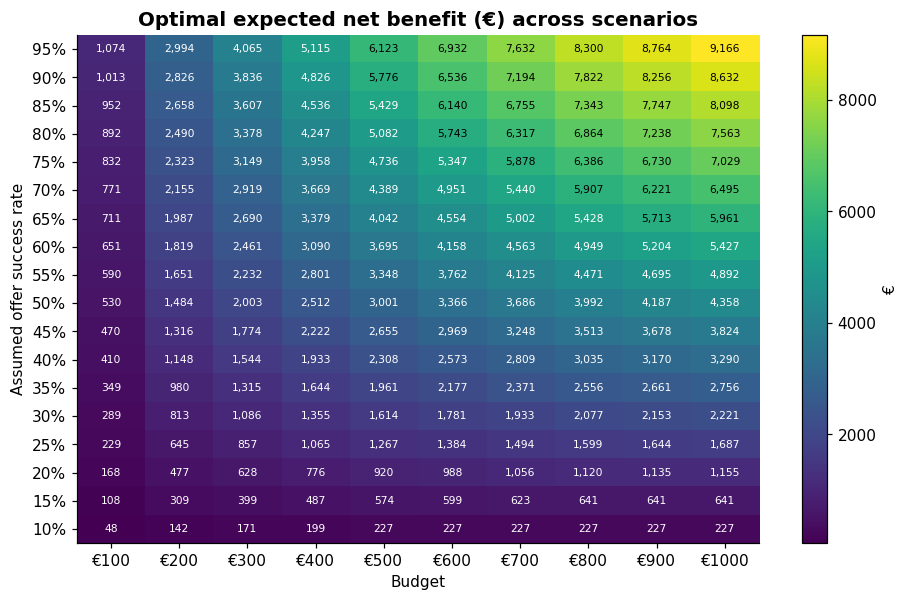

Customer_ID,Times Selected,Selection Frequency
C001,18,100%
C004,18,100%
C007,18,100%
C021,18,100%
C024,18,100%
C030,18,100%


In [8]:
display(success_rate_sensitivity(pilot_raw, [0.30, 0.50, 0.70], PILOT_BUDGET).style
        .format({"Assumed Success Rate": "{:.0%}", "Spending (€)": "€{:,.0f}",
                 "Expected Net Benefit (€)": "€{:,.0f}"}).hide(axis="index"))
display(budget_sensitivity(pilot_raw, [350, 500, 650], SUCCESS_RATE).style
        .format({"Assumed Success Rate": "{:.0%}", "Spending (€)": "€{:,.0f}",
                 "Expected Net Benefit (€)": "€{:,.0f}"}).hide(axis="index"))

rates = np.round(np.arange(0.10, 0.951, 0.05), 2)
grid = sensitivity_grid(pilot_raw, rates, range(100, 1001, 100))
fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(grid.values, aspect="auto", origin="lower", cmap="viridis")
ax.set_xticks(range(grid.shape[1]), [f"€{b}" for b in grid.columns])
ax.set_yticks(range(grid.shape[0]), [f"{r:.0%}" for r in grid.index])
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j]
        ax.text(j, i, f"{v:,.0f}", ha="center", va="center", fontsize=7,
                color="black" if v > grid.values.max() * 0.6 else "white")
ax.set_xlabel("Budget"); ax.set_ylabel("Assumed offer success rate")
ax.set_title("Optimal expected net benefit (€) across scenarios")
fig.colorbar(im, ax=ax, label="€")
save(fig, "A7_sensitivity_heatmap.png")

stability = portfolio_stability(pilot_raw, rates, PILOT_BUDGET)
display(stability.head(8).style.format({"Selection Frequency": "{:.0%}"}).hide(axis="index"))

* Across **every** tested success rate from 10% to 95%, the **recommended accounts do not change**. Only the size of the benefit changes, so the recommendation is robust to the largest uncertainty in the model.
* More budget always helps, but with **diminishing returns**: the first €500 buys far more value than the next €500.
* The stability table confirms that all six recommended accounts are selected in 100% of scenarios. They are the "always fund" core.

## A8. Risk of the recommended portfolio

,Mean Net Benefit (€),Std Dev (€),5th Percentile (€),Median (€),95th Percentile (€),Probability of Loss
Strategy,,,,,,
Random,€569,€915,€-462,€447,"€1,963",33.6%
Highest Churn Probability,"€1,061",€928,€-481,"€1,035","€2,553",16.1%
Value Density (Greedy),"€3,005","€1,918",€-467,"€2,794","€6,133",7.3%
Knapsack Optimization,"€3,005","€1,918",€-467,"€2,794","€6,133",7.3%


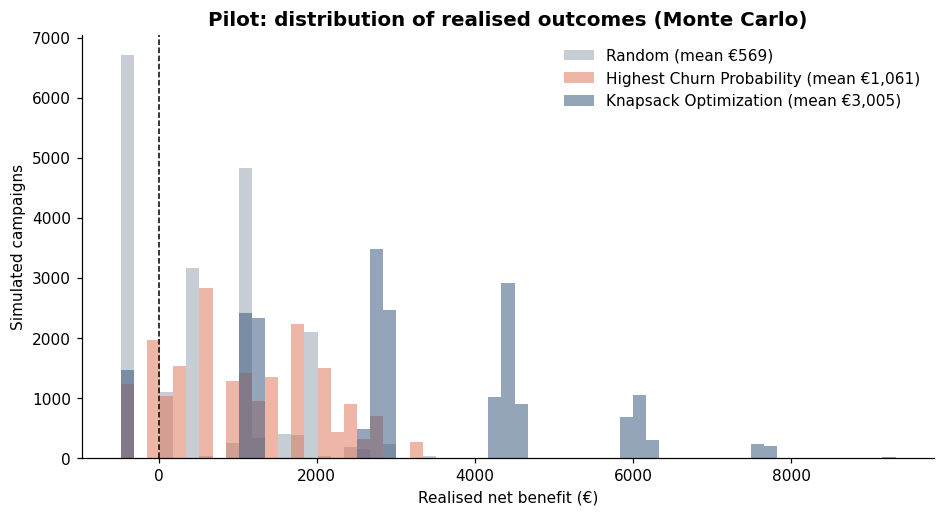

In [9]:
pilot_sims = {k: simulate_net_benefit(pilot, v, SUCCESS_RATE, runs=MC_RUNS, seed=SEED) for k, v in pilot_sel.items()}
pilot_risk = summarise_simulations(pilot_sims)
display(pilot_risk.style.format({c: "€{:,.0f}" for c in pilot_risk.columns if "€" in c} | {"Probability of Loss": "{:.1%}"}))

fig, ax = plt.subplots()
bins = np.linspace(min(s.min() for s in pilot_sims.values()), max(s.max() for s in pilot_sims.values()), 60)
for k in ["Random", "Highest Churn Probability", "Knapsack Optimization"]:
    ax.hist(pilot_sims[k], bins=bins, alpha=0.55, color=COLORS[k], label=f"{k} (mean {euro(pilot_sims[k].mean())})")
ax.axvline(0, color="black", ls="--", lw=1)
ax.set_xlabel("Realised net benefit (€)"); ax.set_ylabel("Simulated campaigns")
ax.set_title("Pilot: distribution of realised outcomes (Monte Carlo)"); ax.legend(frameon=False)
save(fig, "A8_pilot_monte_carlo.png")

The simulated mean matches the analytical expectation, which validates the model. The optimised portfolio has the **highest expected value and the lowest probability of a loss**. The worst case is bounded by the campaign spend.

---
# Part B: Full subscriber base (5,000 accounts)

Following the pilot, the method is applied to the whole subscriber base with a **€25,000 quarterly budget**. The base dataset carries the commercial and behavioural attributes the retention team works with (plan, contract, region, acquisition channel, tenure, viewing hours, support tickets and payment failures), so the recommendation can be explained segment by segment.

## B1. Data overview

In [10]:
base_raw = load_customers(ROOT / BASE_FILE)
failed = [k for k, v in validation_report(base_raw).items() if not v]
print(f"{len(base_raw):,} subscribers | {base_raw.shape[1]} attributes | validation: "
      f"{'all checks passed' if not failed else failed}")
display(base_raw.head(5).style.hide(axis="index").format(precision=2))

mix = pd.concat({c: base_raw[c].value_counts(normalize=True) for c in ["Plan", "Contract", "Region",
                 "Acquisition_Channel"]}).rename("Share").to_frame()
display(mix.style.format("{:.0%}"))

5,000 subscribers | 14 attributes | validation: all checks passed


Customer_ID,Actual_Churn,Predicted_Churn_Probability,Estimated_CLV,Retention_Offer_Cost,Plan,Monthly_Fee,Contract,Region,Acquisition_Channel,Tenure_Months,Viewing_Hours_30d,Support_Tickets_90d,Payment_Failures_90d
AUR-0001,1,0.31,157,29,Standard,12.99,Monthly,Nordics,Organic,6,46.20,0,0
AUR-0002,1,0.28,373,48,Premium,17.99,Annual,Southern Europe,Organic,13,12.40,1,0
AUR-0003,1,0.53,285,48,Premium,17.99,Monthly,Southern Europe,Organic,24,6.60,0,0
AUR-0004,1,0.30,115,19,Basic,7.99,Monthly,UK & Ireland,Organic,17,25.30,0,0
AUR-0005,0,0.54,111,19,Basic,7.99,Monthly,DACH,Organic,15,18.10,0,1


## B2. What drives churn?

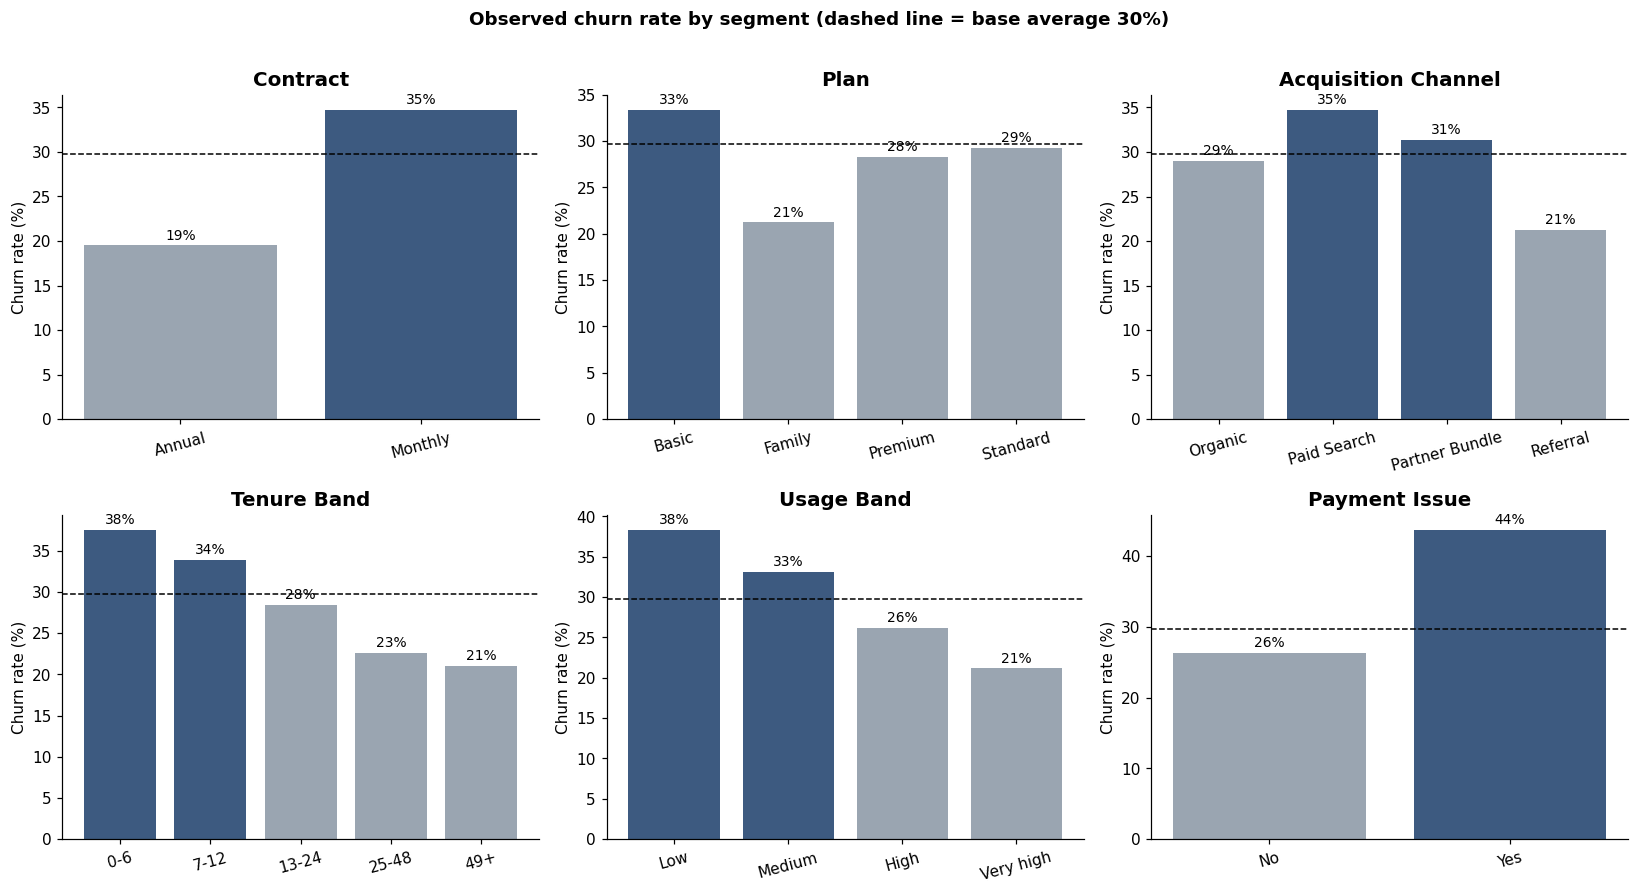

In [11]:
base_raw["Tenure_Band"] = pd.cut(base_raw["Tenure_Months"], [0, 6, 12, 24, 48, 120],
                                 labels=["0-6", "7-12", "13-24", "25-48", "49+"])
base_raw["Usage_Band"] = pd.qcut(base_raw["Viewing_Hours_30d"], 4, labels=["Low", "Medium", "High", "Very high"])
base_raw["Payment_Issue"] = np.where(base_raw["Payment_Failures_90d"] > 0, "Yes", "No")

drivers = ["Contract", "Plan", "Acquisition_Channel", "Tenure_Band", "Usage_Band", "Payment_Issue"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
overall = base_raw["Actual_Churn"].mean()
for ax, col in zip(axes.ravel(), drivers):
    rate = base_raw.groupby(col, observed=True)["Actual_Churn"].mean()
    bars = ax.bar(rate.index.astype(str), rate.values * 100,
                  color=[ACCENT if v > overall else MUTED for v in rate.values])
    ax.bar_label(bars, [f"{v:.0%}" for v in rate.values], padding=2, fontsize=9)
    ax.axhline(overall * 100, color="black", ls="--", lw=1)
    ax.set_title(col.replace("_", " ")); ax.set_ylabel("Churn rate (%)"); ax.tick_params(axis="x", rotation=15)
fig.suptitle(f"Observed churn rate by segment (dashed line = base average {overall:.0%})",
             fontweight="bold", y=1.01)
fig.tight_layout()
save(fig, "B2_churn_drivers.png")

Churn concentrates in subscribers on **monthly contracts**, those with **low viewing hours**, **short tenure**, **failed payments**, and those acquired through **paid search and partner bundles**. These are the segments where a retention offer has the most value at stake. Value and cost still decide who is worth an offer, which is the job of the optimiser.

## B3. How reliable is the churn score?

,Value
ROC AUC,0.705
Brier Score,0.186
Base Churn Rate,0.297
Mean Predicted Probability,0.316


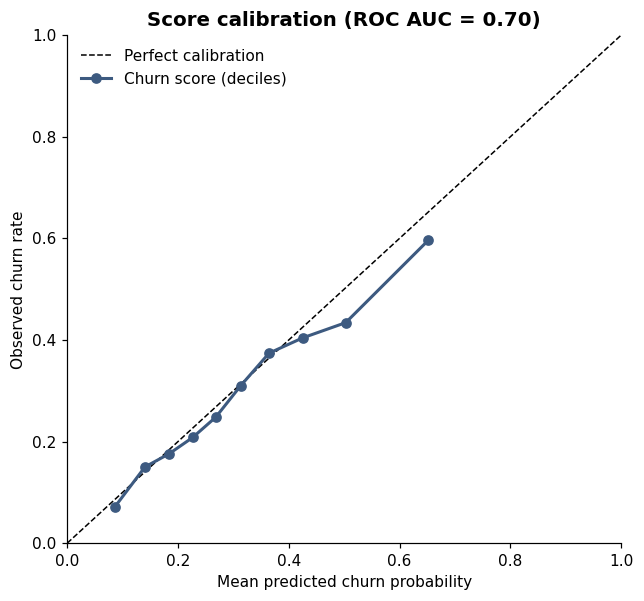

In [12]:
diag, calib = score_diagnostics(base_raw, bins=10)
display(pd.Series(diag).to_frame("Value").style.format("{:.3f}"))

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0, 1], [0, 1], ls="--", color="black", lw=1, label="Perfect calibration")
ax.plot(calib["Mean_Predicted"], calib["Observed_Churn_Rate"], marker="o", color=ACCENT, lw=2, label="Churn score (deciles)")
ax.set_xlabel("Mean predicted churn probability"); ax.set_ylabel("Observed churn rate")
ax.set_title(f"Score calibration (ROC AUC = {diag['ROC AUC']:.2f})"); ax.legend(frameon=False)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
save(fig, "B3_score_calibration.png")

The score separates churners from non-churners usefully (ROC AUC of about 0.70), and its deciles follow the diagonal reasonably closely. It is good enough to drive an expected-value decision. The remaining calibration error is also why Section B7 stress-tests the result instead of trusting point estimates.

## B4. Customer economics at scale

In [13]:
base = add_expected_value(base_raw, SUCCESS_RATE)
base["Break_Even_Success_Rate"] = break_even_success_rate(base)
positive = base["Expected_Net_Benefit"] > 0
print(f"Offers with positive expected net benefit: {positive.sum():,} of {len(base):,} ({positive.mean():.0%})")
print(f"Cost of funding every positive offer: {euro(base.loc[positive, 'Retention_Offer_Cost'].sum())} "
      f"vs. budget {euro(BASE_BUDGET)}, so the budget is binding")

econ = base.groupby("Plan").agg(Subscribers=("Customer_ID", "size"), Avg_CLV=("Estimated_CLV", "mean"),
                                Avg_Offer_Cost=("Retention_Offer_Cost", "mean"),
                                Avg_Churn_Score=("Predicted_Churn_Probability", "mean"),
                                Avg_ENB=("Expected_Net_Benefit", "mean"),
                                Share_Positive=("Expected_Net_Benefit", lambda s: (s > 0).mean()))
display(econ.style.format({"Avg_CLV": "€{:,.0f}", "Avg_Offer_Cost": "€{:,.0f}", "Avg_Churn_Score": "{:.2f}",
                           "Avg_ENB": "€{:,.1f}", "Share_Positive": "{:.0%}"}))

Offers with positive expected net benefit: 2,453 of 5,000 (49%)
Cost of funding every positive offer: €74,297 vs. budget €25,000, so the budget is binding


,Subscribers,Avg_CLV,Avg_Offer_Cost,Avg_Churn_Score,Avg_ENB,Share_Positive
Plan,,,,,,
Basic,1758,€134,€19,0.35,€2.9,57%
Family,490,€498,€60,0.26,€1.3,42%
Premium,999,€309,€48,0.30,€-4.7,36%
Standard,1753,€219,€29,0.31,€2.5,50%


## B5. Optimisation at €25,000

,Selected Customers,Total Spending (€),Expected Retained Value (€),Expected Net Benefit (€),ROI,Actual Churners Captured,Actual Churn Capture Rate,Share of Optimum
Strategy,,,,,,,,
Random,769,"€24,989","€25,890",€901,0.04x,238,16.0%,3.9%
Highest Churn Probability,843,"€24,995","€45,433","€20,438",0.82x,450,30.3%,87.3%
Value Density (Greedy),841,"€25,000","€48,405","€23,405",0.94x,417,28.1%,100.0%
Knapsack Optimization,841,"€25,000","€48,405","€23,405",0.94x,417,28.1%,100.0%


**Value added vs. the current risk-first rule: €2,967 per campaign (+15%) with the same budget.**

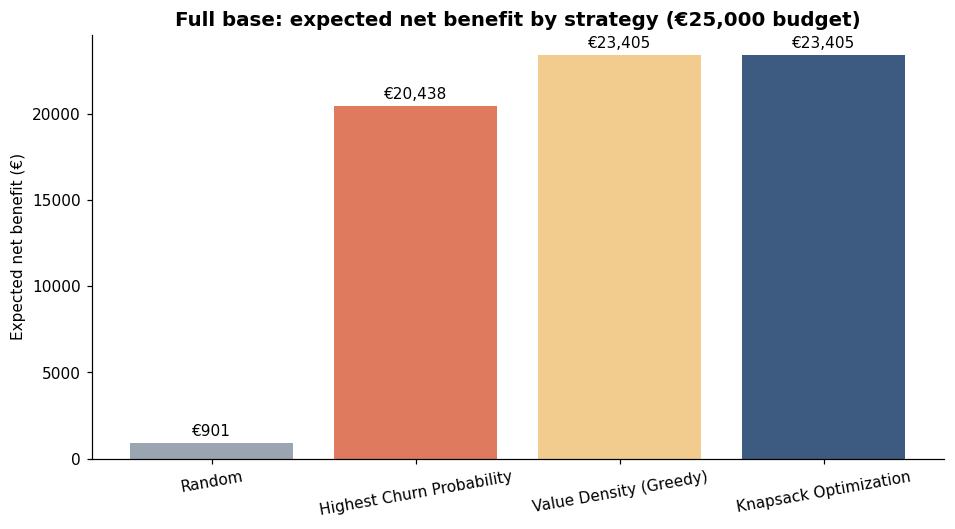

In [14]:
base_sel = run_strategies(base, BASE_BUDGET, seed=SEED)
base_cmp = compare_strategies(base, base_sel)
base_cmp["Share of Optimum"] = optimality_gap(base_cmp)
display(base_cmp.style.format({"Selected Customers": "{:,.0f}", "Total Spending (€)": "€{:,.0f}",
        "Expected Retained Value (€)": "€{:,.0f}", "Expected Net Benefit (€)": "€{:,.0f}", "ROI": "{:.2f}x",
        "Actual Churners Captured": "{:,.0f}", "Actual Churn Capture Rate": "{:.1%}",
        "Share of Optimum": "{:.1%}"}))

uplift = (base_cmp.loc["Knapsack Optimization", "Expected Net Benefit (€)"]
          - base_cmp.loc["Highest Churn Probability", "Expected Net Benefit (€)"])
display(Markdown(f"**Value added vs. the current risk-first rule: {euro(uplift)} per campaign "
                 f"(+{uplift / base_cmp.loc['Highest Churn Probability', 'Expected Net Benefit (€)']:.0%}) "
                 f"with the same budget.**"))

fig, ax = plt.subplots()
vals = base_cmp["Expected Net Benefit (€)"]
bars = ax.bar(vals.index, vals.values, color=[COLORS[i] for i in vals.index])
ax.bar_label(bars, [euro(v) for v in vals.values], padding=3)
ax.set_title(f"Full base: expected net benefit by strategy ({euro(BASE_BUDGET)} budget)")
ax.set_ylabel("Expected net benefit (€)"); ax.tick_params(axis="x", rotation=10)
save(fig, "B5_base_strategy_comparison.png")

Margins are much thinner on the mass-market base than in the pilot: random targeting turns a €25k budget into under €1k of net value. The risk-first rule does far better, but it still leaves about **€3,000 (13% of the achievable value)** on the table in every campaign. The greedy heuristic matches the optimum here, because thousands of small, similar offers make the budget easy to pack. The exact solver costs nothing extra (it runs in well under a second) and removes any doubt.

## B6. Where does the budget go?

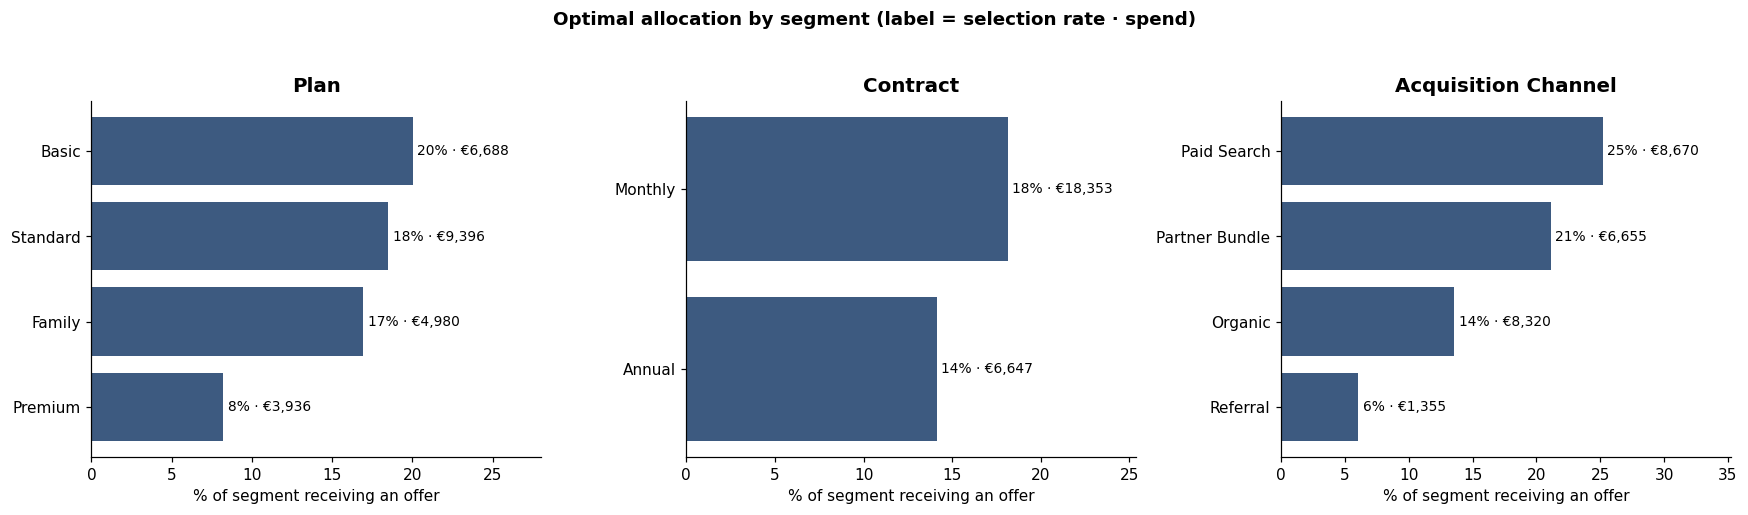

,Customers,Selected,Spend (€),Expected Net Benefit (€),Selection Rate,Share of Spend
Region,,,,,,
DACH,"1,467",274,"€8,373","€7,669",19%,33%
Southern Europe,"1,013",161,"€4,436","€4,154",16%,18%
UK & Ireland,986,153,"€4,422","€4,120",16%,18%
Benelux,790,139,"€4,205","€4,069",18%,17%
Nordics,744,114,"€3,564","€3,394",15%,14%


In [15]:
opt_ids = base_sel["Knapsack Optimization"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ["Plan", "Contract", "Acquisition_Channel"]):
    alloc = segment_allocation(base, opt_ids, col).sort_values("Selection Rate")
    bars = ax.barh(alloc.index, alloc["Selection Rate"] * 100, color=ACCENT)
    ax.bar_label(bars, [f"{r:.0%} · {euro(s)}" for r, s in zip(alloc["Selection Rate"], alloc["Spend (€)"])],
                 padding=3, fontsize=9)
    ax.set_title(col.replace("_", " ")); ax.set_xlabel("% of segment receiving an offer")
    ax.set_xlim(0, alloc["Selection Rate"].max() * 140)
fig.suptitle("Optimal allocation by segment (label = selection rate · spend)", fontweight="bold", y=1.03)
fig.tight_layout()
save(fig, "B6_allocation_by_segment.png")

region = segment_allocation(base, opt_ids, "Region")
display(region.style.format({"Customers": "{:,.0f}", "Selected": "{:,.0f}", "Spend (€)": "€{:,.0f}",
                             "Expected Net Benefit (€)": "€{:,.0f}", "Selection Rate": "{:.0%}",
                             "Share of Spend": "{:.0%}"}))

* **Contract:** monthly subscribers receive offers at a higher rate (18% vs 14%) and take almost three-quarters of the spend.
* **Plan:** Basic and Standard subscribers are targeted most. **Premium is targeted least (8%)**, because its two-and-a-half-month offer is expensive relative to the value at risk. Premium retention therefore needs a cheaper incentive, such as a temporary downgrade path, rather than more budget.
* **Channel:** paid-search and partner-bundle acquisitions are targeted at four times the rate of referrals, which churn rarely.
* **Region** allocation broadly follows market size, so region is not a primary lever.

## B7. How large should the budget be?

Budget (€),Selected Customers,Spending (€),Expected Net Benefit (€),Marginal Return per €
"€5,000",167,"€4,999","€7,590",
"€10,000",337,"€10,000","€12,857",1.05
"€15,000",502,"€15,000","€17,005",0.83
"€20,000",666,"€20,000","€20,444",0.69
"€25,000",841,"€25,000","€23,405",0.59
"€30,000","1,007","€30,000","€25,911",0.50
"€35,000","1,167","€35,000","€28,040",0.43
"€40,000","1,336","€40,000","€29,833",0.36
"€45,000","1,502","€45,000","€31,312",0.30
"€50,000","1,670","€50,000","€32,516",0.24


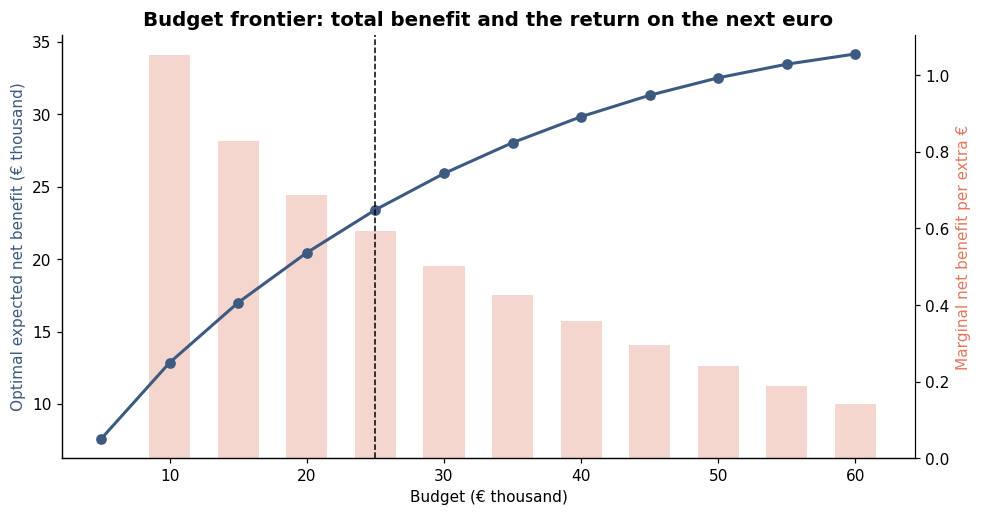

In [16]:
budgets = list(range(5_000, 60_001, 5_000))
frontier = budget_sensitivity(base_raw, budgets, SUCCESS_RATE)
frontier["Marginal Return per €"] = frontier["Expected Net Benefit (€)"].diff() / frontier["Budget (€)"].diff()
display(frontier.drop(columns=["Selected IDs", "Assumed Success Rate"]).style.format(
    {"Budget (€)": "€{:,.0f}", "Selected Customers": "{:,.0f}", "Spending (€)": "€{:,.0f}",
     "Expected Net Benefit (€)": "€{:,.0f}", "Marginal Return per €": "{:.2f}"}, na_rep="").hide(axis="index"))

fig, ax1 = plt.subplots()
ax1.plot(frontier["Budget (€)"] / 1000, frontier["Expected Net Benefit (€)"] / 1000, marker="o", color=ACCENT, lw=2)
ax1.axvline(BASE_BUDGET / 1000, color="black", ls="--", lw=1)
ax1.set_xlabel("Budget (€ thousand)"); ax1.set_ylabel("Optimal expected net benefit (€ thousand)", color=ACCENT)
ax2 = ax1.twinx()
ax2.bar(frontier["Budget (€)"] / 1000, frontier["Marginal Return per €"], width=3, alpha=0.3, color="#E07A5F")
ax2.set_ylabel("Marginal net benefit per extra €", color="#E07A5F"); ax2.spines["right"].set_visible(True)
ax1.set_zorder(ax2.get_zorder() + 1); ax1.patch.set_visible(False)
ax1.set_title("Budget frontier: total benefit and the return on the next euro")
save(fig, "B7_budget_frontier.png")

Each additional euro of budget earns less than the one before. As long as the marginal return per euro stays above zero, a larger budget still adds value, but at a declining rate. The client can set the budget where the marginal return falls to its hurdle rate. Beyond the point where every positive-value offer is funded, extra budget adds nothing.

## B8. Risk and retrospective check

,Mean Net Benefit (€),Std Dev (€),5th Percentile (€),Median (€),95th Percentile (€),Probability of Loss
Strategy,,,,,,
Random,€880,"€2,394","€-2,966",€842,"€4,869",36.1%
Highest Churn Probability,"€20,441","€2,678","€16,075","€20,446","€24,823",0.0%
Value Density (Greedy),"€23,395","€3,045","€18,450","€23,376","€28,410",0.0%
Knapsack Optimization,"€23,395","€3,045","€18,450","€23,376","€28,410",0.0%


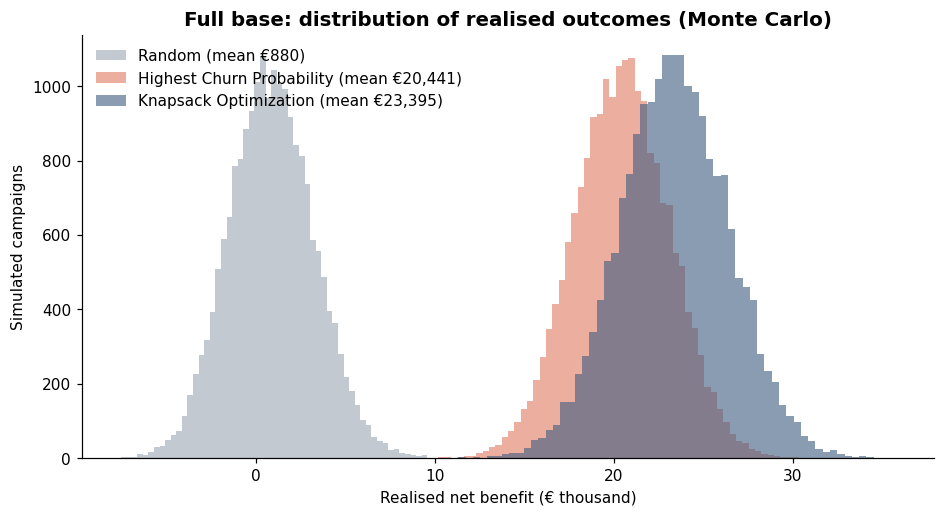

In [17]:
base_sims = {k: simulate_net_benefit(base, v, SUCCESS_RATE, runs=MC_RUNS, seed=SEED) for k, v in base_sel.items()}
base_risk = summarise_simulations(base_sims)
display(base_risk.style.format({c: "€{:,.0f}" for c in base_risk.columns if "€" in c} | {"Probability of Loss": "{:.1%}"}))

fig, ax = plt.subplots()
for k in ["Random", "Highest Churn Probability", "Knapsack Optimization"]:
    ax.hist(base_sims[k] / 1000, bins=60, alpha=0.6, color=COLORS[k], label=f"{k} (mean {euro(base_sims[k].mean())})")
ax.set_xlabel("Realised net benefit (€ thousand)"); ax.set_ylabel("Simulated campaigns")
ax.set_title("Full base: distribution of realised outcomes (Monte Carlo)"); ax.legend(frameon=False)
save(fig, "B8_base_monte_carlo.png")

With hundreds of offers, outcomes average out: the optimised campaign is **profitable in every simulated scenario**, and in 95% of scenarios it returns at least about €18,000. Random targeting loses money in more than a third of scenarios. The retrospective churn-capture figures in B5 are descriptive only. Proving causal impact requires a randomised hold-out group (see Section 4).

---
# Part C: Beyond the base model

Part B assumed one offer per subscriber, a single budget limit and the same 50% success rate for everyone. Part C relaxes each assumption on the full base, with the same €25,000 budget.

## C1. Choosing the offer per subscriber

Offer,Assumed success rate,Free months,Handling (€),Monthly contracts only
Loyalty email,10%,0,€3,False
One free month,32%,1,€3,False
Two free months,50%,2,€3,False
Annual-plan discount,62%,3,€3,True


,Subscribers Targeted,Total Spending (€),Expected Net Benefit (€)
Policy,,,
Everyone: Loyalty email,"4,305","€12,915","€18,947"
Everyone: One free month,"1,500","€25,000","€27,441"
Everyone: Two free months,820,"€25,000","€26,869"
Everyone: Annual-plan discount,557,"€24,999","€19,137"
Best offer per subscriber (MCKP),"3,004","€25,000","€33,875"


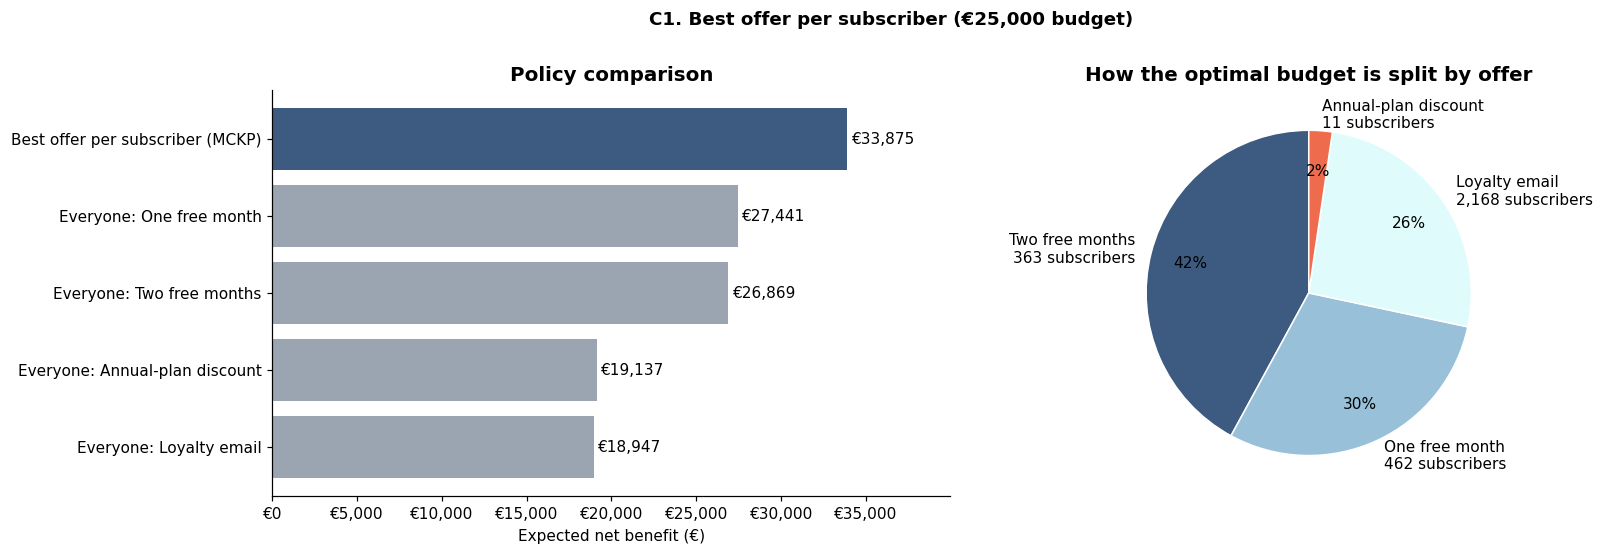

**Choosing the offer per subscriber adds €6,434 (+23%) over the best one-size-fits-all policy and reaches 3,004 subscribers.**

In [18]:
from odin.offers import DEFAULT_CATALOGUE, build_offer_menu, compare_offer_policies, multi_offer_selection, offer_mix

catalogue = pd.DataFrame([{"Offer": o.name, "Assumed success rate": o.success_rate,
                           "Free months": o.cost_months, "Handling (€)": o.fixed_cost,
                           "Monthly contracts only": o.monthly_only} for o in DEFAULT_CATALOGUE])
display(catalogue.style.format({"Assumed success rate": "{:.0%}", "Free months": "{:g}",
                                "Handling (€)": "€{:,.0f}"}).hide(axis="index"))

menu = build_offer_menu(base_raw)
policies = compare_offer_policies(menu, BASE_BUDGET)
mckp = multi_offer_selection(menu, BASE_BUDGET)
mix = offer_mix(mckp)
display(policies.style.format({"Subscribers Targeted": "{:,.0f}", "Total Spending (€)": "€{:,.0f}",
                               "Expected Net Benefit (€)": "€{:,.0f}"}))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.4, 1]})
vals = policies["Expected Net Benefit (€)"].sort_values()
bars = ax1.barh(vals.index, vals.values, color=[ACCENT if "MCKP" in i else MUTED for i in vals.index])
ax1.bar_label(bars, [euro(v) for v in vals.values], padding=3)
ax1.set_xlim(0, vals.max() * 1.18); ax1.set_xlabel("Expected net benefit (€)")
ax1.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: euro(v)))
ax1.set_title("Policy comparison")
ax2.pie(mix["Spend"], labels=[f"{o}\n{n:,} subscribers" for o, n in zip(mix.index, mix["Subscribers"])],
        colors=["#3D5A80", "#98C1D9", "#E0FBFC", "#EE6C4D"][: len(mix)], startangle=90,
        wedgeprops={"edgecolor": "white"}, autopct="%1.0f%%", pctdistance=0.75)
ax2.set_title("How the optimal budget is split by offer")
fig.suptitle(f"C1. Best offer per subscriber ({euro(BASE_BUDGET)} budget)", fontweight="bold", y=1.03)
save(fig, "C1_offer_choice.png")

best_single = policies.drop(index="Best offer per subscriber (MCKP)")["Expected Net Benefit (€)"].max()
display(Markdown(f"**Choosing the offer per subscriber adds {euro(mckp['Offer_Net_Benefit'].sum() - best_single)} "
                 f"(+{mckp['Offer_Net_Benefit'].sum() / best_single - 1:.0%}) over the best one-size-fits-all policy "
                 f"and reaches {len(mckp):,} subscribers.**"))

Most subscribers get the cheap loyalty email, and the free months go where the value at risk justifies them. The annual-plan discount is rarely worth its cost. This is a **multiple-choice knapsack**, solved exactly by dynamic programming and verified against exhaustive search in the test suite.

## C2. What do operational limits cost?

,Unconstrained (€),Constrained (€),Cost of Constraints (€),Share Retained
DACH at most 25% of spend,"€33,875","€33,739",€136,99.6%
Nordics at least 300 contacts,"€33,875","€33,875",€-0,100.0%
"All three (incl. 1,500 contacts)","€33,875","€31,240","€2,635",92.2%


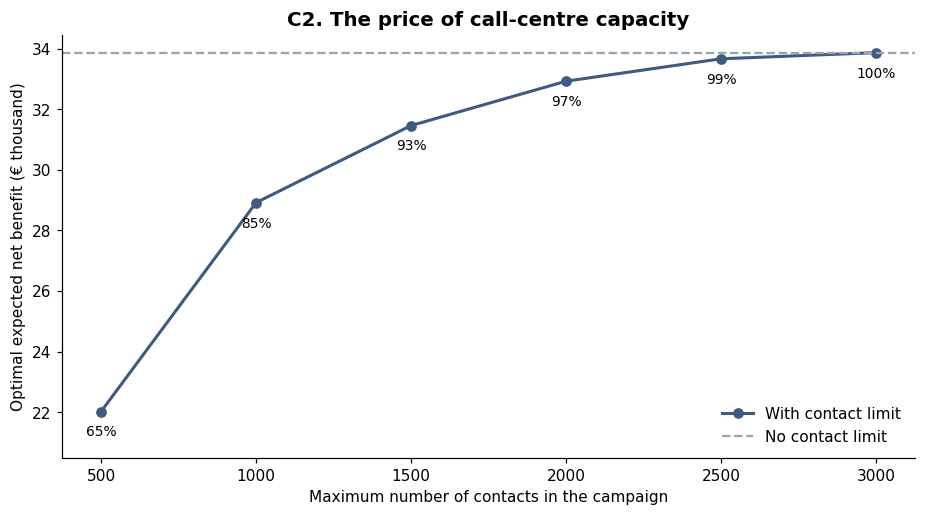

In [19]:
from odin.constraints import CampaignConstraints, shadow_cost

regions = base_raw.set_index("Customer_ID")["Region"]
capacity_levels = [500, 1_000, 1_500, 2_000, 2_500, 3_000]
capacity = pd.DataFrame([{"Maximum contacts": k, **shadow_cost(menu, BASE_BUDGET, CampaignConstraints(max_contacts=k))}
                         for k in capacity_levels])
quota_rules = {
    "DACH at most 25% of spend": CampaignConstraints(segment_column="Region", max_spend_share={"DACH": 0.25}),
    "Nordics at least 300 contacts": CampaignConstraints(segment_column="Region", min_contacts={"Nordics": 300}),
    "All three (incl. 1,500 contacts)": CampaignConstraints(max_contacts=1_500, segment_column="Region",
                                                           max_spend_share={"DACH": 0.25},
                                                           min_contacts={"Nordics": 300}),
}
quotas = pd.DataFrame({k: shadow_cost(menu, BASE_BUDGET, v, regions) for k, v in quota_rules.items()}).T
display(quotas.style.format({c: "€{:,.0f}" for c in quotas.columns if "€" in c} | {"Share Retained": "{:.1%}"}))

fig, ax = plt.subplots()
ax.plot(capacity["Maximum contacts"], capacity["Constrained (€)"] / 1000, marker="o", color=ACCENT, lw=2,
        label="With contact limit")
ax.axhline(capacity["Unconstrained (€)"].iloc[0] / 1000, color=MUTED, ls="--", label="No contact limit")
for _, r in capacity.iterrows():
    ax.annotate(f"{r['Share Retained']:.0%}", (r["Maximum contacts"], r["Constrained (€)"] / 1000),
                textcoords="offset points", xytext=(0, -16), ha="center", fontsize=9)
ax.set_xlabel("Maximum number of contacts in the campaign")
ax.set_ylabel("Optimal expected net benefit (€ thousand)")
ax.set_ylim(capacity["Constrained (€)"].min() / 1000 * 0.93, None)
ax.set_title("C2. The price of call-centre capacity"); ax.legend(frameon=False, loc="lower right")
save(fig, "C2_contact_capacity.png")

With several constraints the problem is a general 0/1 integer programme, solved exactly with HiGHS. **Contact capacity is the constraint that matters:** below about 1,500 contacts the campaign gives up noticeable value, so extra call-centre capacity has a measurable price. Regional quotas cost almost nothing, so they can be adopted for strategic reasons.

## C3. Who actually responds? Uplift modelling

,Selected Customers,Total Spending (€),True Retained Value (€),True Net Benefit (€),Expected Churns Prevented
Highest churn probability,843,"€24,995","€26,905","€1,910",179
"Knapsack, constant 50% rate",841,"€25,000","€25,854",€854,151
"Knapsack, uplift model","1,020","€25,000","€39,279","€14,279",267
"Knapsack, true uplift (oracle)","1,005","€25,000","€40,219","€15,219",269


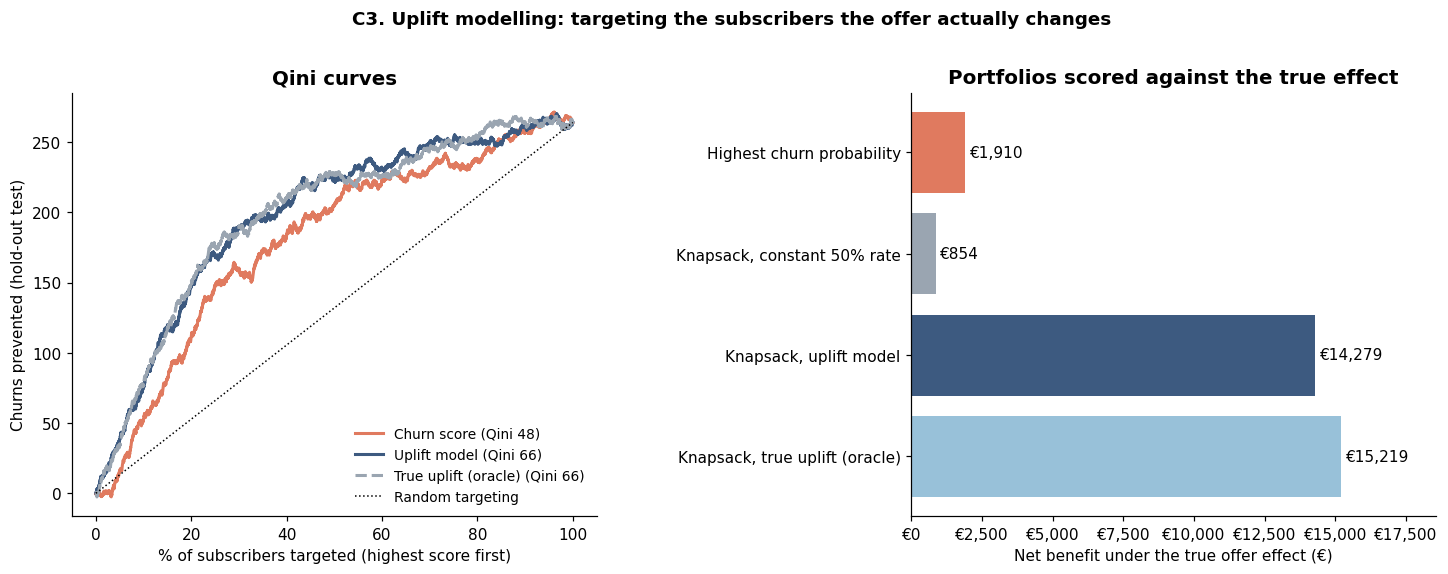

Correlation of estimated with true uplift: 0.96


In [20]:
from odin.uplift import (TLearner, add_uplift_value, qini_coefficient, qini_curve, realised_value,
                         simulate_campaign_experiment, true_uplift)
from odin.synthetic import generate_customer_base

warnings.filterwarnings("ignore")
cohort = generate_customer_base(20_000, seed=101)            # a past campaign, run as a randomised test
experiment = simulate_campaign_experiment(cohort, seed=1)
model = TLearner().fit(experiment)

est = model.predict(base_raw)
truth = true_uplift(base_raw)
holdout = simulate_campaign_experiment(base_raw, seed=2)
curves = {
    "Churn score": qini_curve(base_raw["Predicted_Churn_Probability"], holdout["Treatment"], holdout["Churned"]),
    "Uplift model": qini_curve(model.predict(holdout), holdout["Treatment"], holdout["Churned"]),
    "True uplift (oracle)": qini_curve(truth, holdout["Treatment"], holdout["Churned"]),
}
constant = add_expected_value(base_raw, SUCCESS_RATE)
portfolios = {
    "Highest churn probability": base_sel["Highest Churn Probability"],
    "Knapsack, constant 50% rate": knapsack_selection(constant, BASE_BUDGET),
    "Knapsack, uplift model": knapsack_selection(add_uplift_value(base_raw, est), BASE_BUDGET),
    "Knapsack, true uplift (oracle)": knapsack_selection(add_uplift_value(base_raw, truth), BASE_BUDGET),
}
uplift_cmp = pd.DataFrame({k: realised_value(base_raw, v, truth) for k, v in portfolios.items()}).T
display(uplift_cmp.style.format({"Selected Customers": "{:,.0f}", "Total Spending (€)": "€{:,.0f}",
                                 "True Retained Value (€)": "€{:,.0f}", "True Net Benefit (€)": "€{:,.0f}",
                                 "Expected Churns Prevented": "{:,.0f}"}))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"wspace": 0.6})
for (name, curve), color in zip(curves.items(), ["#E07A5F", ACCENT, MUTED]):
    ax1.plot(curve["Share_Targeted"] * 100, curve["Incremental_Saves"], color=color, lw=2,
             ls="--" if "oracle" in name else "-", label=f"{name} (Qini {qini_coefficient(curve):.0f})")
end = curves["Churn score"]["Incremental_Saves"].iloc[-1]
ax1.plot([0, 100], [0, end], color="black", lw=1, ls=":", label="Random targeting")
ax1.set_xlabel("% of subscribers targeted (highest score first)"); ax1.set_ylabel("Churns prevented (hold-out test)")
ax1.set_title("Qini curves"); ax1.legend(frameon=False, fontsize=9)
vals = uplift_cmp["True Net Benefit (€)"]
bars = ax2.barh(vals.index, vals.values, color=["#E07A5F", MUTED, ACCENT, "#98C1D9"])
ax2.bar_label(bars, [euro(v) for v in vals.values], padding=3); ax2.invert_yaxis()
ax2.set_xlim(0, vals.max() * 1.22); ax2.set_xlabel("Net benefit under the true offer effect (€)")
ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: euro(v)))
ax2.set_title("Portfolios scored against the true effect")
fig.suptitle("C3. Uplift modelling: targeting the subscribers the offer actually changes", fontweight="bold", y=1.03)
save(fig, "C3_uplift.png")
print(f"Correlation of estimated with true uplift: {np.corrcoef(est, truth)[0, 1]:.2f}")

The offer does not work equally well for everyone. In this simulated world monthly subscribers and new joiners are persuadable, subscribers with payment failures leave whatever happens, and a small group of heavy viewers with open support tickets reacts *badly* to being contacted.

* A **T-learner** (one churn model for offered and one for held-out subscribers) trained on a randomised past campaign recovers each subscriber's uplift with a correlation of about 0.96. Its Qini curve almost matches the oracle's, and it ranks subscribers far better than the churn score.
* **The warning:** when the effect varies, a knapsack fed a single assumed success rate optimises the wrong quantity. Here it does *worse* than the risk-first rule. The uplift-based portfolio recovers about 94% of the oracle's value.

This is the quantitative case for Recommendation 3: **a randomised hold-out is worth more than any further refinement of the optimiser.** The true effect here is defined by the synthetic generator, so the figures demonstrate the method, not a measured outcome.

---
# 4. Recommendations

1. **Replace the risk-first targeting rule with value-based optimisation.** Under the stated assumptions this adds about €3,000 (+15%) of expected net benefit per €25k campaign, with no increase in spend.
2. **Focus offers where risk, value and offer cost line up:** monthly contracts, Basic and Standard plans, and paid-search and partner-bundle acquisitions. **Redesign the Premium offer**: at its current cost it rarely pays back.
3. **Run the next campaign as a randomised test.** Hold out a random 10–20% of the selected subscribers. Comparing churn between treated and held-out subscribers measures the true offer effect, the single most important assumption. Part C shows that per-subscriber uplift estimated from such a test can be worth far more than further optimisation.
4. **Let the model choose the offer, and price capacity.** Choosing the offer per subscriber adds about a quarter to expected net benefit (C1). Contact capacity is the operational limit worth relaxing; regional quotas are nearly free (C2).
5. **Set the budget using the frontier (B7).** Fund the campaign up to the point where the marginal return per euro falls to the client's hurdle rate.
6. **Operationalise.** The `odin` package exposes the full pipeline (`python -m odin analyze`), so the list can be refreshed every cycle from the latest churn scores.

# 5. Limitations

* **Synthetic data.** Both datasets are synthetic replicas generated for this case study. Results illustrate the method and are not measured business outcomes.
* **Assumed offer effectiveness.** The 50% success rate is a scenario input, which is why the report stress-tests it from 10% to 95%.
* **Simplified economics.** CLV is margin-based but undiscounted. Partial retention, offer-specific effects and cannibalisation are not modelled.
* **No causal claim.** Observed churn among selected subscribers is descriptive. Causal impact requires the experiment in recommendation 3.
* **Simulated treatment effects.** Part C estimates uplift from a *simulated* randomised campaign. In production it needs a real hold-out experiment.

---
# Appendix: Reproducibility and exported artefacts

Every table below is written to `outputs/report/tables/` and every chart to `outputs/report/figures/`. Paths are shown relative to the repository root.

In [21]:
exports = {
    "pilot_customer_economics.csv": pilot,
    "pilot_strategy_comparison.csv": pilot_cmp,
    "pilot_recommended_portfolio.csv": portfolio,
    "pilot_sensitivity_grid.csv": grid,
    "pilot_portfolio_stability.csv": stability,
    "pilot_monte_carlo_risk.csv": pilot_risk,
    "pilot_heuristic_gap.csv": gap,
    "base_strategy_comparison.csv": base_cmp,
    "base_recommended_portfolio.csv": base[base["Customer_ID"].isin(opt_ids)],
    "base_allocation_by_region.csv": region,
    "base_budget_frontier.csv": frontier,
    "base_monte_carlo_risk.csv": base_risk,
    "base_score_calibration.csv": calib,
    "ext_offer_policies.csv": policies,
    "ext_offer_mix.csv": mix,
    "ext_contact_capacity.csv": capacity,
    "ext_segment_quotas.csv": quotas,
    "ext_uplift_portfolios.csv": uplift_cmp,
}
for name, table in exports.items():
    table.to_csv(ROOT / TAB / name, index=not isinstance(table.index, pd.RangeIndex))

print("Tables:")
for p in sorted((ROOT / TAB).glob("*.csv")):
    print("  ", p.relative_to(ROOT))
print("Figures:")
for p in sorted((ROOT / FIG).glob("*.png")):
    print("  ", p.relative_to(ROOT))

Tables:
   outputs/report/tables/base_allocation_by_region.csv
   outputs/report/tables/base_budget_frontier.csv
   outputs/report/tables/base_monte_carlo_risk.csv
   outputs/report/tables/base_recommended_portfolio.csv
   outputs/report/tables/base_score_calibration.csv
   outputs/report/tables/base_strategy_comparison.csv
   outputs/report/tables/ext_contact_capacity.csv
   outputs/report/tables/ext_offer_mix.csv
   outputs/report/tables/ext_offer_policies.csv
   outputs/report/tables/ext_segment_quotas.csv
   outputs/report/tables/ext_uplift_portfolios.csv
   outputs/report/tables/pilot_customer_economics.csv
   outputs/report/tables/pilot_heuristic_gap.csv
   outputs/report/tables/pilot_monte_carlo_risk.csv
   outputs/report/tables/pilot_portfolio_stability.csv
   outputs/report/tables/pilot_recommended_portfolio.csv
   outputs/report/tables/pilot_sensitivity_grid.csv
   outputs/report/tables/pilot_strategy_comparison.csv
Figures:
   outputs/report/figures/A2_pilot_profile.png
   o